# Progressive chess outcome prediction

**CA6001 — AI Algorithms Fundamentals & Application**  
**Data:** [Chess Game Dataset (Lichess), Kaggle](https://www.kaggle.com/datasets/datasnaek/chess)

## Research question

How accurately can the three-class result of a chess game (`black`, `draw`, `white`) be predicted before play, and how quickly does predictive performance improve as moves become available?

This notebook is the complete, reproducible analysis. It maps directly to the brief's learning outcomes: explain and compare algorithms, justify choices from data, implement a working solution, and evaluate it with suitable metrics.

### Experimental design

1. Download, inspect, clean, and split by **game** into train/validation/test sets.
2. Build a pre-match baseline from only information genuinely known before the first move: ratings, rated/casual status, and time control.
3. Replay training and validation games with `python-chess` and sample positions at fixed ply counts.
4. Compare material-only and richer handcrafted position features using histogram gradient boosting.
5. Compare them with a small CNN trained directly on 17 board planes.
6. Select and fuse models using fixed-ply validation snapshots, then evaluate the untouched test set retrospectively at 10%, 25%, 50%, 75%, and 100% of each recorded move list.

> **Leakage boundary.** `winner`, `victory_status`, total turns/duration, opening labels, player IDs, future moves, and percentage progress are never model inputs. Every in-game model receives only the current board and current `ply`; the CNN and stacker apply a fixed scaling to `ply` that does not use final game length. Percentage checkpoints use final length only to group retrospective test evaluation. A final board alone cannot reveal who won by resignation or timeout, so the 100% point remains a pure prediction and is not forced to perfect accuracy.

In [1]:
from __future__ import annotations

import hashlib
import io
import os
import random
import urllib.request
import warnings
import zipfile
from pathlib import Path

import chess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

SEED = 6001
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print({
    "python_seed": SEED,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "python_chess": chess.__version__,
    "torch": torch.__version__,
    "device": str(DEVICE),
})

{'python_seed': 6001, 'pandas': '3.1.0', 'scikit_learn': '1.9.1', 'python_chess': '1.11.2', 'torch': '2.14.1+cpu', 'device': 'cpu'}


## 1. Acquire the source data

The public Kaggle API endpoint does not require credentials for this dataset. The cell is idempotent: it downloads only when `data/games.csv` is absent, verifies that the archive contains the expected member, writes to a temporary file, and atomically replaces the destination. The printed SHA-256 digest makes the exact input auditable.

In [2]:
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/datasnaek/chess"
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR / "games.csv"


def acquire_data(url: str = DATA_URL, destination: Path = CSV_PATH) -> Path:
    """Download and atomically materialize the public Kaggle CSV when needed."""
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        if "games.csv" not in archive.namelist():
            raise RuntimeError("The downloaded archive does not contain games.csv.")
        payload = archive.read("games.csv")
    temporary = destination.with_suffix(".csv.tmp")
    temporary.write_bytes(payload)
    temporary.replace(destination)
    return destination


source_path = acquire_data()
source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
print(f"Source: {source_path.resolve()}")
print(f"Size: {source_path.stat().st_size / 1_000_000:.2f} MB")
print(f"SHA-256: {source_hash}")

Source: /home/gushucheng/Chess/data/games.csv
Size: 7.67 MB
SHA-256: e7aadff104a610afb5403caf81c1461babecb0dc87760ff5eea7dc0e7a4a8129


## 2. Initial inspection, cleaning, and data split

The target is genuinely multiclass. Macro-F1 is the primary selection metric because a high overall accuracy can conceal failure on the comparatively rare draw class; accuracy and multiclass log loss are reported alongside it. Duplicates are removed before splitting, and the split is stratified by outcome. A fixed random seed makes it reproducible.

In [3]:
raw = pd.read_csv(source_path)
print(f"Raw shape: {raw.shape}")
display(raw.head(3))

inspection = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
    "unique": raw.nunique(dropna=False),
})
display(inspection)
print(f"Duplicate game IDs: {raw['id'].duplicated().sum()}")
print("Outcome counts:")
display(raw["winner"].value_counts(dropna=False).to_frame("count"))

Raw shape: (20058, 16)


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3


,dtype,missing,missing_pct,unique
id,str,0,0.0,19113
rated,bool,0,0.0,2
created_at,float64,0,0.0,13151
last_move_at,float64,0,0.0,13186
turns,int64,0,0.0,211
victory_status,str,0,0.0,4
winner,str,0,0.0,3
increment_code,str,0,0.0,400
white_id,str,0,0.0,9438
white_rating,int64,0,0.0,1516


Duplicate game IDs: 945
Outcome counts:


,count
winner,
white,10001
black,9107
draw,950


In [4]:
VALID_WINNERS = {"black", "draw", "white"}
LABEL_TO_INT = {"black": 0, "draw": 1, "white": 2}
CLASS_NAMES = np.array(["black", "draw", "white"])


def clean_games(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Apply explicit quality rules and return clean rows plus an audit trail."""
    audit = {}
    work = frame.copy()
    audit["raw_rows"] = len(work)
    work = work.drop_duplicates(subset="id", keep="first")
    audit["duplicate_ids_removed"] = audit["raw_rows"] - len(work)

    valid_target = work["winner"].isin(VALID_WINNERS)
    valid_ratings = work["white_rating"].between(100, 4000) & work["black_rating"].between(100, 4000)
    valid_moves = work["moves"].fillna("").str.strip().ne("")
    parsed_time = work["increment_code"].astype(str).str.extract(r"^(\d+)\+(\d+)$").astype(float)
    valid_time = parsed_time.notna().all(axis=1)
    keep = valid_target & valid_ratings & valid_moves & valid_time
    audit["invalid_target_removed"] = int((~valid_target).sum())
    audit["invalid_rating_removed"] = int((~valid_ratings).sum())
    audit["empty_move_list_removed"] = int((~valid_moves).sum())
    audit["invalid_time_control_removed"] = int((~valid_time).sum())

    work = work.loc[keep].copy().reset_index(drop=True)
    parsed_time = parsed_time.loc[keep].reset_index(drop=True)
    work["base_minutes"] = parsed_time[0].astype(int)
    work["increment_seconds"] = parsed_time[1].astype(int)
    work["rated_int"] = work["rated"].astype(int)
    work["move_count"] = work["moves"].str.split().str.len()
    work["rating_diff"] = work["white_rating"] - work["black_rating"]
    work["rating_mean"] = (work["white_rating"] + work["black_rating"]) / 2
    work["rating_gap"] = work["rating_diff"].abs()
    work["log_base_minutes"] = np.log1p(work["base_minutes"])
    work["white_elo_expectation"] = 1 / (1 + 10 ** (-work["rating_diff"] / 400))
    work["target"] = work["winner"].map(LABEL_TO_INT).astype(int)
    audit["clean_rows"] = len(work)
    return work, pd.Series(audit, name="count")


games, cleaning_audit = clean_games(raw)
display(cleaning_audit.to_frame())
print(f"Clean shape: {games.shape}")
print("Declared turns minus tokenized SAN count:")
display((games["turns"] - games["move_count"]).value_counts().head().to_frame("games"))

,count
raw_rows,20058
duplicate_ids_removed,945
invalid_target_removed,0
invalid_rating_removed,0
empty_move_list_removed,0
invalid_time_control_removed,0
clean_rows,19113


Clean shape: (19113, 26)
Declared turns minus tokenized SAN count:


,games
0,19113


In [5]:
all_indices = np.arange(len(games))
train_idx, holdout_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=games["target"],
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=games.loc[holdout_idx, "target"],
)

split_by_index = np.full(len(games), "", dtype=object)
split_by_index[train_idx] = "train"
split_by_index[val_idx] = "validation"
split_by_index[test_idx] = "test"
games["split"] = split_by_index

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert games["id"].is_unique

split_summary = (
    games.groupby(["split", "winner"], observed=True)
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
)
display(split_summary)

winner,black,draw,white,total
split,,,,
test,1302,133,1432,2867
train,6076,622,6681,13379
validation,1302,133,1432,2867


## 3. Pre-match statistics, correlation analysis, and visualisation

`opening_eco`, `opening_name`, and `opening_ply` are derived from moves and are therefore excluded from pre-match modelling. Player IDs are also excluded: memorising frequent players would weaken generalisation to unseen players. Game duration, final turn count, and termination status become known only after or during play and are outcome-leaking for the pre-match task.

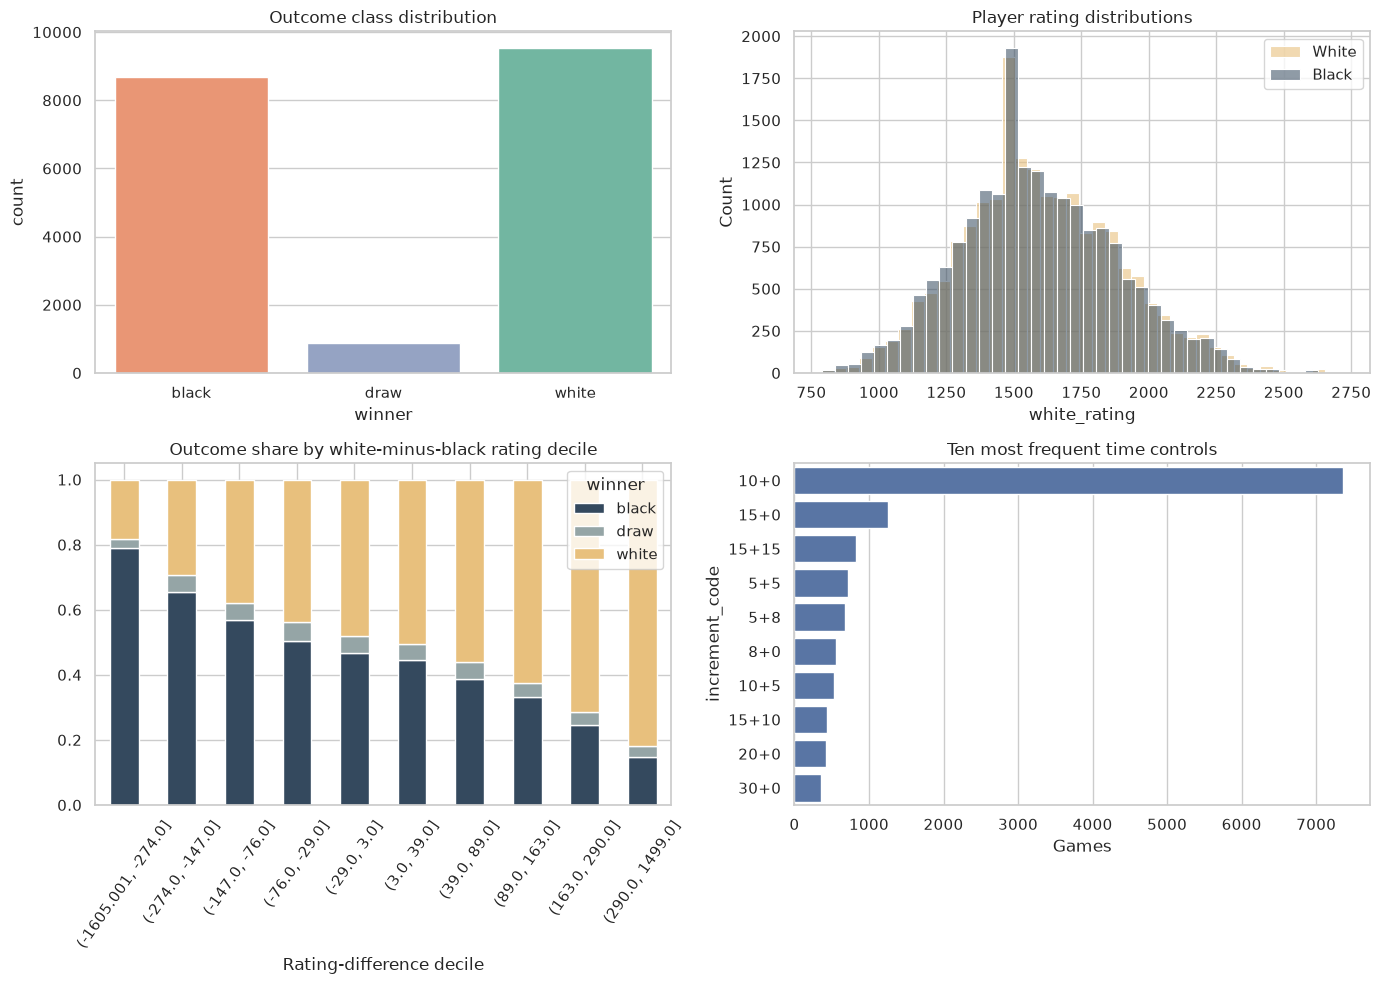

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=games, x="winner", order=CLASS_NAMES, ax=axes[0, 0], palette="Set2", hue="winner", legend=False)
axes[0, 0].set_title("Outcome class distribution")

sns.histplot(games["white_rating"], bins=40, color="#e8c07d", alpha=0.6, label="White", ax=axes[0, 1])
sns.histplot(games["black_rating"], bins=40, color="#34495e", alpha=0.55, label="Black", ax=axes[0, 1])
axes[0, 1].legend()
axes[0, 1].set_title("Player rating distributions")

rating_bins = pd.qcut(games["rating_diff"], q=10, duplicates="drop")
win_by_rating = pd.crosstab(rating_bins, games["winner"], normalize="index")
win_by_rating.plot(kind="bar", stacked=True, color=["#34495e", "#95a5a6", "#e8c07d"], ax=axes[1, 0])
axes[1, 0].set_title("Outcome share by white-minus-black rating decile")
axes[1, 0].set_xlabel("Rating-difference decile")
axes[1, 0].tick_params(axis="x", labelrotation=55)

top_controls = games["increment_code"].value_counts().head(10).index
sns.countplot(
    data=games[games["increment_code"].isin(top_controls)],
    y="increment_code",
    order=top_controls,
    ax=axes[1, 1],
    color="#4c72b0",
)
axes[1, 1].set_title("Ten most frequent time controls")
axes[1, 1].set_xlabel("Games")

plt.tight_layout()
fig.savefig(FIGURE_DIR / "01_eda_overview.png", dpi=300, bbox_inches="tight")
plt.show()

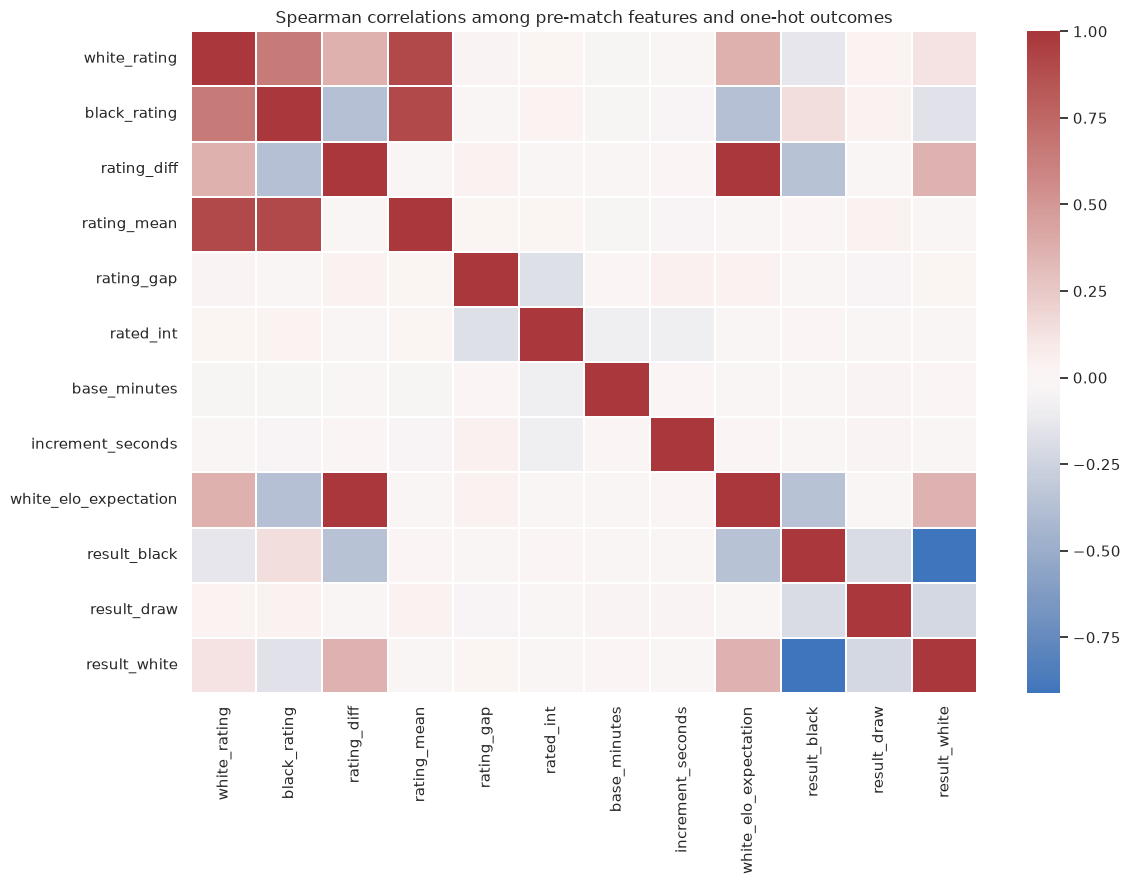

white_rating                 black_rating                 rating_diff  \
               mean  median     std         mean  median     std        mean   
winner                                                                         
black       1550.82  1527.0  282.50      1639.27  1610.0  289.45      -88.45   
draw        1649.32  1623.5  308.86      1642.19  1627.0  301.63        7.13   
white       1634.73  1603.0  288.76      1540.43  1517.0  281.71       94.30   

                      rating_gap                base_minutes                
       median     std       mean median     std         mean median    std  
winner                                                                      
black   -52.0  229.32     171.52  114.5  176.03        13.52   10.0  16.41  
draw     -2.5  210.33     144.33   93.5  153.08        16.59   10.0  24.38  
white    59.0  234.03     175.68  117.0  181.09        13.77   10.0  16.81

In [7]:
correlation_frame = games[[
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "white_elo_expectation",
]].copy()
outcome_dummies = pd.get_dummies(games["winner"], prefix="result", dtype=float)
corr = pd.concat([correlation_frame, outcome_dummies], axis=1).corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, square=False, linewidths=0.3)
plt.title("Spearman correlations among pre-match features and one-hot outcomes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_prematch_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

display(
    games.groupby("winner")[["white_rating", "black_rating", "rating_diff", "rating_gap", "base_minutes"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

## 4. Pre-match models

Three levels are compared:

- majority-class dummy: a necessary sanity baseline;
- class-balanced multinomial logistic regression: a transparent linear AI model;
- histogram gradient boosting: a nonlinear tree ensemble in the same broad boosting family as XGBoost, chosen here because it is fast, supports missing-value-safe tabular learning, and is already maintained in scikit-learn.

Class-balanced fitting emphasises macro-F1 and gives draws meaningful influence. Model selection uses validation macro-F1 only; the test set is touched once after selection.

In [8]:
PREMATCH_FEATURES = [
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "log_base_minutes",
    "white_elo_expectation",
]


def metric_row(name: str, y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    predictions = probabilities.argmax(axis=1)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1, 2]),
    }


X_train_pre = games.loc[train_idx, PREMATCH_FEATURES]
y_train = games.loc[train_idx, "target"].to_numpy()
X_val_pre = games.loc[val_idx, PREMATCH_FEATURES]
y_val = games.loc[val_idx, "target"].to_numpy()
X_test_pre = games.loc[test_idx, PREMATCH_FEATURES]
y_test = games.loc[test_idx, "target"].to_numpy()

class_counts = np.bincount(y_train, minlength=3)
class_weights = len(y_train) / (3 * class_counts)
train_sample_weights = class_weights[y_train]

prematch_candidates = {
    "Majority dummy": DummyClassifier(strategy="prior"),
    "Balanced logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=SEED)),
    ]),
    "Histogram gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.07,
        max_iter=250,
        max_leaf_nodes=23,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    ),
}

validation_rows = []
for name, model in prematch_candidates.items():
    if name == "Histogram gradient boosting":
        model.fit(X_train_pre, y_train, sample_weight=train_sample_weights)
    else:
        model.fit(X_train_pre, y_train)
    validation_rows.append(metric_row(name, y_val, model.predict_proba(X_val_pre)))

prematch_validation = pd.DataFrame(validation_rows).sort_values("macro_f1", ascending=False)
display(prematch_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

best_prematch_name = prematch_validation.iloc[0]["model"]
best_prematch = prematch_candidates[best_prematch_name]
prematch_test_proba = best_prematch.predict_proba(X_test_pre)
prematch_test_metrics = pd.DataFrame([metric_row(best_prematch_name, y_test, prematch_test_proba)])
print(f"Selected pre-match model: {best_prematch_name}")
display(prematch_test_metrics.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

,model,accuracy,macro_f1,log_loss
2,Histogram gradient boosting,0.497,0.400,0.987
1,Balanced logistic regression,0.473,0.393,1.025
0,Majority dummy,0.499,0.222,0.848


Selected pre-match model: Histogram gradient boosting


,model,accuracy,macro_f1,log_loss
0,Histogram gradient boosting,0.523,0.427,0.980


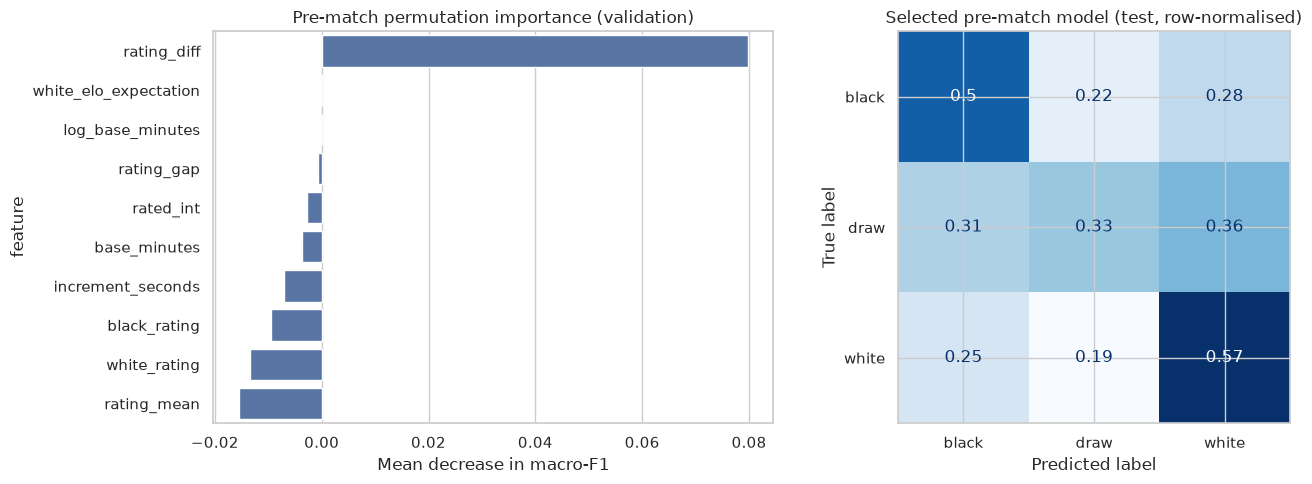

              precision    recall  f1-score   support

       black      0.619     0.496     0.551      1302
        draw      0.074     0.331     0.121       133
       white      0.659     0.566     0.609      1432

    accuracy                          0.523      2867
   macro avg      0.451     0.464     0.427      2867
weighted avg      0.614     0.523     0.560      2867



In [9]:
importance = permutation_importance(
    best_prematch,
    X_val_pre,
    y_val,
    scoring="f1_macro",
    n_repeats=8,
    random_state=SEED,
    n_jobs=-1,
)
importance_frame = pd.DataFrame({
    "feature": PREMATCH_FEATURES,
    "mean_macro_f1_drop": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=importance_frame, x="mean_macro_f1_drop", y="feature", color="#4c72b0", ax=axes[0])
axes[0].set_title("Pre-match permutation importance (validation)")
axes[0].set_xlabel("Mean decrease in macro-F1")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prematch_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Blues",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Selected pre-match model (test, row-normalised)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_prematch_importance_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(y_test, prematch_test_proba.argmax(axis=1), target_names=CLASS_NAMES, digits=3, zero_division=0))

## 5. Replay games and engineer position features

Each game is parsed from the initial position. Training and validation positions are sampled at predetermined ply counts (ply 4, then every 8 plies from 8 through 160), which are known without looking ahead to the eventual game length. Only test evaluation uses retrospective percentage checkpoints. Features are always oriented from White's perspective.

**Material group:** piece-count differences, standard material balance, and bishop-pair advantage.  
**Positional additions:** mobility, centre attacks, pawn shield, doubled/isolated/passed pawns, castling rights, check status, side to move, and current ply.

The ablation directly measures the incremental contribution of richer position structure over material alone. No engine evaluation is used, so the comparison remains an interpretable feature-learning experiment.

In [10]:
TRAINING_PLIES = (4, *range(8, 161, 8))
EVALUATION_FRACTIONS = (0.10, 0.25, 0.50, 0.75, 1.00)
PLY_SCALE = 100.0
PIECE_VALUES = {
    chess.PAWN: 1.0,
    chess.KNIGHT: 3.0,
    chess.BISHOP: 3.25,
    chess.ROOK: 5.0,
    chess.QUEEN: 9.0,
}
PIECE_NAMES = {
    chess.PAWN: "pawn",
    chess.KNIGHT: "knight",
    chess.BISHOP: "bishop",
    chess.ROOK: "rook",
    chess.QUEEN: "queen",
}
CENTER_SQUARES = [chess.D4, chess.E4, chess.D5, chess.E5]


def legal_move_count(board: chess.Board, color: chess.Color) -> int:
    """Count legal moves after setting the side to move on a copied board."""
    copy = board.copy(stack=False)
    copy.turn = color
    return copy.legal_moves.count()


def pawn_structure(board: chess.Board, color: chess.Color) -> tuple[int, int, int]:
    """Return doubled, isolated, and passed pawn counts for one color."""
    pawn_squares = list(board.pieces(chess.PAWN, color))
    files = [chess.square_file(square) for square in pawn_squares]
    doubled = sum(max(files.count(file_index) - 1, 0) for file_index in set(files))
    isolated = sum(
        not any(abs(chess.square_file(other) - chess.square_file(square)) == 1 for other in pawn_squares)
        for square in pawn_squares
    )
    enemy_pawns = list(board.pieces(chess.PAWN, not color))
    passed = 0
    for square in pawn_squares:
        file_index, rank_index = chess.square_file(square), chess.square_rank(square)
        blockers = []
        for enemy in enemy_pawns:
            enemy_file, enemy_rank = chess.square_file(enemy), chess.square_rank(enemy)
            ahead = enemy_rank > rank_index if color == chess.WHITE else enemy_rank < rank_index
            blockers.append(ahead and abs(enemy_file - file_index) <= 1)
        passed += not any(blockers)
    return int(doubled), int(isolated), int(passed)


def king_shield(board: chess.Board, color: chess.Color) -> int:
    """Count friendly pawns on adjacent squares around the king."""
    king_square = board.king(color)
    if king_square is None:
        return 0
    return sum(
        board.piece_at(square) == chess.Piece(chess.PAWN, color)
        for square in chess.SquareSet(chess.BB_KING_ATTACKS[king_square])
    )


def board_features(board: chess.Board, ply: int) -> dict[str, float]:
    """Create interpretable material and positional features from a board."""
    features: dict[str, float] = {}
    material_balance = 0.0
    for piece_type, piece_name in PIECE_NAMES.items():
        white_count = len(board.pieces(piece_type, chess.WHITE))
        black_count = len(board.pieces(piece_type, chess.BLACK))
        difference = white_count - black_count
        features[f"{piece_name}_diff"] = difference
        material_balance += PIECE_VALUES[piece_type] * difference
    features["material_balance"] = material_balance
    features["bishop_pair_diff"] = int(len(board.pieces(chess.BISHOP, chess.WHITE)) >= 2) - int(
        len(board.pieces(chess.BISHOP, chess.BLACK)) >= 2
    )

    features["mobility_diff"] = legal_move_count(board, chess.WHITE) - legal_move_count(board, chess.BLACK)
    features["center_control_diff"] = sum(
        len(board.attackers(chess.WHITE, square)) - len(board.attackers(chess.BLACK, square))
        for square in CENTER_SQUARES
    )
    features["king_shield_diff"] = king_shield(board, chess.WHITE) - king_shield(board, chess.BLACK)

    white_structure = pawn_structure(board, chess.WHITE)
    black_structure = pawn_structure(board, chess.BLACK)
    for name, white_value, black_value in zip(
        ("doubled_pawn_diff", "isolated_pawn_diff", "passed_pawn_diff"),
        white_structure,
        black_structure,
    ):
        features[name] = white_value - black_value

    features["castling_rights_diff"] = (
        int(board.has_kingside_castling_rights(chess.WHITE))
        + int(board.has_queenside_castling_rights(chess.WHITE))
        - int(board.has_kingside_castling_rights(chess.BLACK))
        - int(board.has_queenside_castling_rights(chess.BLACK))
    )
    features["white_in_check"] = int(board.turn == chess.WHITE and board.is_check())
    features["black_in_check"] = int(board.turn == chess.BLACK and board.is_check())
    features["white_to_move"] = int(board.turn == chess.WHITE)
    features["ply"] = ply
    return features


def board_planes(board: chess.Board) -> np.ndarray:
    """Encode a board as 12 piece, 1 turn, and 4 castling-right planes."""
    planes = np.zeros((17, 8, 8), dtype=np.uint8)
    for square, piece in board.piece_map().items():
        offset = 0 if piece.color == chess.WHITE else 6
        channel = offset + piece.piece_type - 1
        row = 7 - chess.square_rank(square)
        column = chess.square_file(square)
        planes[channel, row, column] = 1
    planes[12, :, :] = int(board.turn == chess.WHITE)
    planes[13, :, :] = int(board.has_kingside_castling_rights(chess.WHITE))
    planes[14, :, :] = int(board.has_queenside_castling_rights(chess.WHITE))
    planes[15, :, :] = int(board.has_kingside_castling_rights(chess.BLACK))
    planes[16, :, :] = int(board.has_queenside_castling_rights(chess.BLACK))
    return planes

In [11]:
def extract_snapshots(frame: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DataFrame]:
    """Replay games and extract fixed-ply modelling or percentage evaluation snapshots."""
    records = []
    tensors = []
    failures = []
    for game_index, row in frame.iterrows():
        record_start = len(records)
        tensor_start = len(tensors)
        tokens = row["moves"].split()

        if row["split"] == "test":
            targets = {
                max(1, min(len(tokens), int(round(len(tokens) * fraction)))): ("percentage_evaluation", fraction)
                for fraction in EVALUATION_FRACTIONS
            }
        else:
            targets = {
                ply: ("fixed_ply_modelling", -1.0)
                for ply in TRAINING_PLIES
                if ply <= len(tokens)
            }

        board = chess.Board()
        try:
            for ply, san in enumerate(tokens, start=1):
                board.push_san(san)
                if ply in targets:
                    sampling_scheme, checkpoint = targets[ply]
                    record = {
                        "game_index": game_index,
                        "game_id": row["id"],
                        "split": row["split"],
                        "target": row["target"],
                        "sampling_scheme": sampling_scheme,
                        "checkpoint": checkpoint,
                        "ply": ply,
                    }
                    record.update(board_features(board, ply))
                    records.append(record)
                    tensors.append(board_planes(board))
        except ValueError as error:
            failures.append({"game_index": game_index, "game_id": row["id"], "reason": str(error)})
            del records[record_start:]
            del tensors[tensor_start:]

    snapshot_frame = pd.DataFrame.from_records(records)
    board_tensor = np.stack(tensors) if tensors else np.empty((0, 17, 8, 8), dtype=np.uint8)
    return snapshot_frame, board_tensor, pd.DataFrame(failures)


snapshots, boards, parse_failures = extract_snapshots(games)
assert len(snapshots) == len(boards)
assert not snapshots.isna().any().any()
assert snapshots.loc[snapshots["split"].isin(["train", "validation"]), "checkpoint"].eq(-1.0).all()
print(f"Snapshots: {len(snapshots):,}; board tensor: {boards.shape}; memory: {boards.nbytes / 1_000_000:.1f} MB")
print(f"Games with SAN parsing failures: {len(parse_failures)}")
if len(parse_failures):
    display(parse_failures.head())
display(snapshots.groupby(["split", "sampling_scheme"]).size().to_frame("snapshots"))
display(
    snapshots.loc[snapshots["split"].eq("test")]
    .groupby("checkpoint")
    .size()
    .rename("test_games")
    .to_frame()
)

Snapshots: 146,111; board tensor: (146111, 17, 8, 8); memory: 159.0 MB
Games with SAN parsing failures: 0


,,snapshots
split,sampling_scheme,
test,percentage_evaluation,14179
train,fixed_ply_modelling,108534
validation,fixed_ply_modelling,23398


,test_games
checkpoint,
0.10,2803
0.25,2830
0.50,2849
0.75,2830
1.00,2867


If a future version of the source contains malformed SAN, the failure table makes exclusions explicit. All snapshots from a failed game must be excluded as a group; the supplied dataset is expected to parse cleanly.

In [12]:
MATERIAL_FEATURES = [
    "pawn_diff", "knight_diff", "bishop_diff", "rook_diff", "queen_diff",
    "material_balance", "bishop_pair_diff", "ply",
]
POSITIONAL_FEATURES = MATERIAL_FEATURES + [
    "mobility_diff", "center_control_diff", "king_shield_diff", "doubled_pawn_diff",
    "isolated_pawn_diff", "passed_pawn_diff", "castling_rights_diff",
    "white_in_check", "black_in_check", "white_to_move",
]

snapshot_masks = {name: snapshots["split"].eq(name).to_numpy() for name in ("train", "validation", "test")}
y_snapshot = snapshots["target"].to_numpy()
snapshot_class_counts = np.bincount(y_snapshot[snapshot_masks["train"]], minlength=3)
snapshot_class_weights = snapshot_masks["train"].sum() / (3 * snapshot_class_counts)
snapshot_train_weights = snapshot_class_weights[y_snapshot[snapshot_masks["train"]]]

handcrafted_models = {}
handcrafted_validation_rows = []
for name, features in {
    "Material only": MATERIAL_FEATURES,
    "Material + positional": POSITIONAL_FEATURES,
}.items():
    model = HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=220,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    )
    model.fit(
        snapshots.loc[snapshot_masks["train"], features],
        y_snapshot[snapshot_masks["train"]],
        sample_weight=snapshot_train_weights,
    )
    handcrafted_models[name] = (model, features)
    probabilities = model.predict_proba(snapshots.loc[snapshot_masks["validation"], features])
    handcrafted_validation_rows.append(metric_row(name, y_snapshot[snapshot_masks["validation"]], probabilities))

handcrafted_validation = pd.DataFrame(handcrafted_validation_rows).sort_values("macro_f1", ascending=False)
display(handcrafted_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

best_handcrafted_name = handcrafted_validation.iloc[0]["model"]
best_handcrafted, best_handcrafted_features = handcrafted_models[best_handcrafted_name]
handcrafted_test_proba = best_handcrafted.predict_proba(
    snapshots.loc[snapshot_masks["test"], best_handcrafted_features]
)
display(pd.DataFrame([
    metric_row(best_handcrafted_name, y_snapshot[snapshot_masks["test"]], handcrafted_test_proba)
]).style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

,model,accuracy,macro_f1,log_loss
1,Material + positional,0.557,0.468,0.939
0,Material only,0.548,0.457,0.962


,model,accuracy,macro_f1,log_loss
0,Material + positional,0.602,0.480,0.881


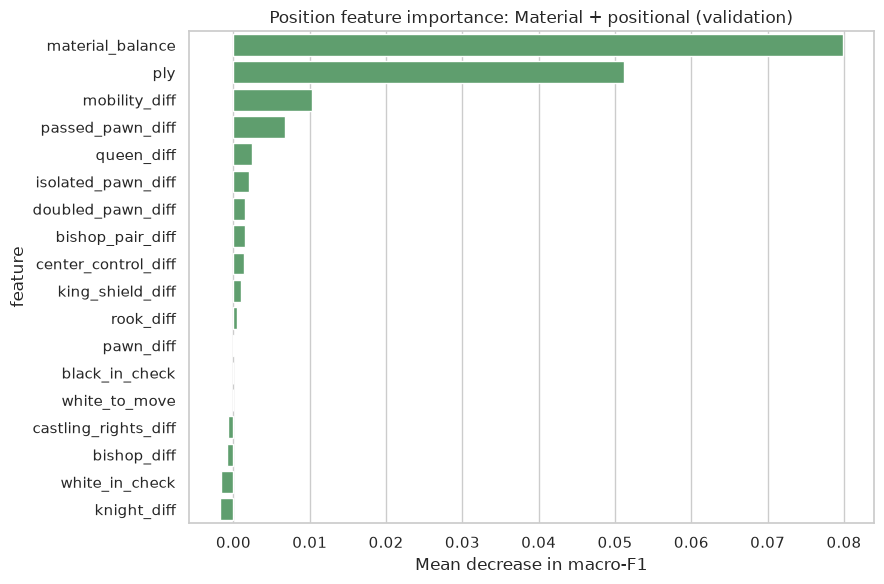

In [13]:
handcrafted_importance = permutation_importance(
    best_handcrafted,
    snapshots.loc[snapshot_masks["validation"], best_handcrafted_features],
    y_snapshot[snapshot_masks["validation"]],
    scoring="f1_macro",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)
handcrafted_importance_frame = pd.DataFrame({
    "feature": best_handcrafted_features,
    "mean_macro_f1_drop": handcrafted_importance.importances_mean,
    "std": handcrafted_importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=handcrafted_importance_frame, x="mean_macro_f1_drop", y="feature", color="#55a868")
plt.title(f"Position feature importance: {best_handcrafted_name} (validation)")
plt.xlabel("Mean decrease in macro-F1")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_position_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. CNN position model

The CNN receives no handcrafted chess score. Its 17 binary planes contain 12 colour-specific piece maps, side to move, and four castling rights. Two convolutional blocks learn local spatial patterns; global pooling makes a compact position representation, which is concatenated with the current ply divided by a fixed constant (`PLY_SCALE = 100`). This scaling uses no future game information. Weighted cross-entropy addresses class imbalance. Early stopping selects the epoch with best validation macro-F1 on fixed-ply snapshots.

This is deliberately a small CPU-friendly architecture: the goal is a controlled algorithm comparison, not an expensive chess engine.

Epoch 01 | train loss 1.0344 | val macro-F1 0.3878


Epoch 02 | train loss 0.9920 | val macro-F1 0.3652


Epoch 03 | train loss 0.9761 | val macro-F1 0.4449


Epoch 04 | train loss 0.9603 | val macro-F1 0.4645


Epoch 05 | train loss 0.9455 | val macro-F1 0.4343


Epoch 06 | train loss 0.9340 | val macro-F1 0.3838


Epoch 07 | train loss 0.9154 | val macro-F1 0.4261
Early stopping triggered.


,model,accuracy,macro_f1,log_loss
0,CNN (validation),0.581,0.465,0.920
1,CNN (test),0.594,0.433,1.448


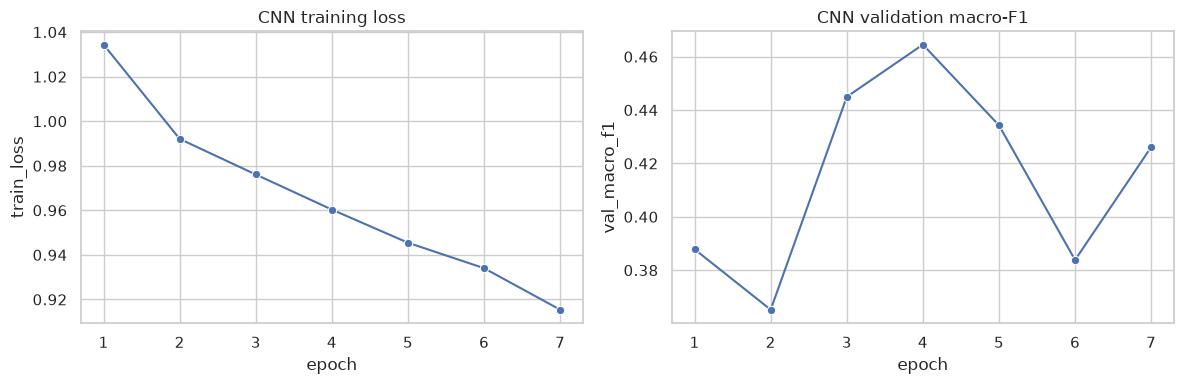

In [14]:
class SnapshotDataset(Dataset):
    def __init__(self, board_array, ply_array, target_array, indices):
        self.board_array = board_array
        self.ply_array = ply_array.astype(np.float32)
        self.target_array = target_array.astype(np.int64)
        self.indices = np.flatnonzero(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        index = self.indices[item]
        return (
            torch.from_numpy(self.board_array[index].astype(np.float32)),
            torch.tensor([self.ply_array[index] / PLY_SCALE], dtype=torch.float32),
            torch.tensor(self.target_array[index], dtype=torch.long),
        )


class PositionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(17, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Linear(65, 48),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(48, 3),
        )

    def forward(self, board_input, ply_input):
        embedding = self.features(board_input).flatten(1)
        return self.classifier(torch.cat([embedding, ply_input], dim=1))


def predict_cnn(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    probabilities, targets = [], []
    with torch.no_grad():
        for board_batch, ply_batch, target_batch in loader:
            logits = model(board_batch.to(DEVICE), ply_batch.to(DEVICE))
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
            targets.append(target_batch.numpy())
    return np.concatenate(probabilities), np.concatenate(targets)


ply_values = snapshots["ply"].to_numpy(dtype=np.float32)
train_dataset = SnapshotDataset(boards, ply_values, y_snapshot, snapshot_masks["train"])
val_dataset = SnapshotDataset(boards, ply_values, y_snapshot, snapshot_masks["validation"])
test_dataset = SnapshotDataset(boards, ply_values, y_snapshot, snapshot_masks["test"])

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=0)

cnn = PositionCNN().to(DEVICE)
loss_weights = torch.tensor(snapshot_class_weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=loss_weights)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)

best_state = None
best_val_f1 = -np.inf
patience = 3
epochs_without_improvement = 0
history = []
for epoch in range(1, 13):
    cnn.train()
    running_loss = 0.0
    for board_batch, ply_batch, target_batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = cnn(board_batch.to(DEVICE), ply_batch.to(DEVICE))
        loss = criterion(logits, target_batch.to(DEVICE))
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(target_batch)

    val_proba_epoch, val_targets_epoch = predict_cnn(cnn, val_loader)
    val_f1_epoch = f1_score(val_targets_epoch, val_proba_epoch.argmax(axis=1), average="macro", zero_division=0)
    history.append({
        "epoch": epoch,
        "train_loss": running_loss / len(train_dataset),
        "val_macro_f1": val_f1_epoch,
    })
    print(f"Epoch {epoch:02d} | train loss {history[-1]['train_loss']:.4f} | val macro-F1 {val_f1_epoch:.4f}")
    if val_f1_epoch > best_val_f1 + 1e-4:
        best_val_f1 = val_f1_epoch
        best_state = {key: value.detach().cpu().clone() for key, value in cnn.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

cnn.load_state_dict(best_state)
cnn.to(DEVICE)
cnn_val_proba, cnn_val_targets = predict_cnn(cnn, val_loader)
cnn_test_proba, cnn_test_targets = predict_cnn(cnn, test_loader)

cnn_results = pd.DataFrame([
    metric_row("CNN (validation)", cnn_val_targets, cnn_val_proba),
    metric_row("CNN (test)", cnn_test_targets, cnn_test_proba),
])
display(cnn_results.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=history_frame, x="epoch", y="train_loss", marker="o", ax=axes[0])
sns.lineplot(data=history_frame, x="epoch", y="val_macro_f1", marker="o", ax=axes[1])
axes[0].set_title("CNN training loss")
axes[1].set_title("CNN validation macro-F1")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "05_cnn_training_history.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Select and combine the position model with pre-match evidence

Selection uses pooled validation macro-F1 across fixed-ply snapshots only. Probability-level fusion is a compact form of stacking: a multinomial logistic regression learns when to trust pre-match strength versus current-board evidence. Its inputs are log probabilities from both base models plus current ply divided by the same fixed constant. The stacker is trained on fixed-ply validation snapshots, while final estimates are produced at retrospective percentage checkpoints on untouched test games.

This separation is important: base models never fit validation or test labels; the meta-model never fits test labels; and final game length is used only to define the reporting checkpoints.

In [15]:
handcrafted_val_proba = best_handcrafted.predict_proba(
    snapshots.loc[snapshot_masks["validation"], best_handcrafted_features]
)
position_validation = pd.DataFrame([
    metric_row(best_handcrafted_name, y_snapshot[snapshot_masks["validation"]], handcrafted_val_proba),
    metric_row("CNN", cnn_val_targets, cnn_val_proba),
]).sort_values("macro_f1", ascending=False)
display(position_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

best_position_name = position_validation.iloc[0]["model"]
if best_position_name == "CNN":
    position_val_proba = cnn_val_proba
    position_test_proba = cnn_test_proba
else:
    position_val_proba = handcrafted_val_proba
    position_test_proba = handcrafted_test_proba
print(f"Selected position model: {best_position_name}")

,model,accuracy,macro_f1,log_loss
0,Material + positional,0.557,0.468,0.939
1,CNN,0.581,0.465,0.920


Selected position model: Material + positional


In [16]:
def probabilities_by_game(model, frame: pd.DataFrame) -> dict[int, np.ndarray]:
    probabilities = model.predict_proba(frame[PREMATCH_FEATURES])
    return dict(zip(frame.index.to_numpy(), probabilities))


prematch_probability_map = probabilities_by_game(best_prematch, games)


def stack_inputs(snapshot_subset: pd.DataFrame, position_probabilities: np.ndarray) -> np.ndarray:
    pre_probabilities = np.stack(snapshot_subset["game_index"].map(prematch_probability_map))
    epsilon = 1e-7
    return np.column_stack([
        np.log(np.clip(pre_probabilities, epsilon, 1)),
        np.log(np.clip(position_probabilities, epsilon, 1)),
        snapshot_subset["ply"].to_numpy() / PLY_SCALE,
    ])


validation_snapshots = snapshots.loc[snapshot_masks["validation"]].reset_index(drop=True)
test_snapshots = snapshots.loc[snapshot_masks["test"]].reset_index(drop=True)
X_stack_val = stack_inputs(validation_snapshots, position_val_proba)
X_stack_test = stack_inputs(test_snapshots, position_test_proba)

stacker = LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=SEED)
stacker.fit(X_stack_val, validation_snapshots["target"])
combined_test_proba = stacker.predict_proba(X_stack_test)

overall_comparison = pd.DataFrame([
    metric_row("Position only", test_snapshots["target"].to_numpy(), position_test_proba),
    metric_row("Pre-match + position", test_snapshots["target"].to_numpy(), combined_test_proba),
])
display(overall_comparison.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

,model,accuracy,macro_f1,log_loss
0,Position only,0.602,0.480,0.881
1,Pre-match + position,0.641,0.516,0.864


,progress_pct,accuracy,macro_f1,n
0,0,0.523,0.427,2867
1,10,0.599,0.409,2803
2,25,0.611,0.447,2830
3,50,0.582,0.470,2849
4,75,0.625,0.524,2830
5,100,0.788,0.659,2867


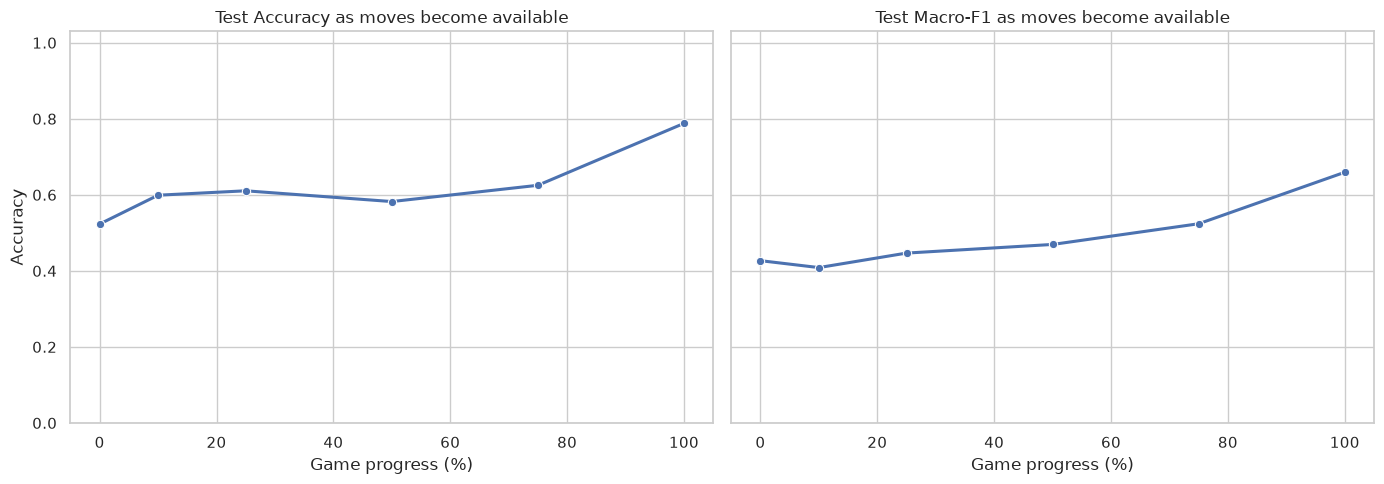

,area_under_accuracy_progress_curve,area_under_macro_f1_progress_curve
0,0.623,0.493


In [17]:
curve_rows = []

# The 0% point is evaluated once per test game using the selected pre-match model.
curve_rows.append({
    "progress_pct": 0,
    "accuracy": accuracy_score(y_test, prematch_test_proba.argmax(axis=1)),
    "macro_f1": f1_score(y_test, prematch_test_proba.argmax(axis=1), average="macro", zero_division=0),
    "n": len(y_test),
})

for checkpoint in EVALUATION_FRACTIONS:
    mask = test_snapshots["checkpoint"].eq(checkpoint).to_numpy()
    targets = test_snapshots.loc[mask, "target"].to_numpy()
    predictions = combined_test_proba[mask].argmax(axis=1)
    curve_rows.append({
        "progress_pct": int(checkpoint * 100),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
        "n": len(targets),
    })

model_curve = pd.DataFrame(curve_rows).sort_values("progress_pct")
display(model_curve.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for axis, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro-F1"]):
    sns.lineplot(data=model_curve, x="progress_pct", y=metric, marker="o", linewidth=2.2, ax=axis)
    axis.set_ylim(0, 1.03)
    axis.set_xlabel("Game progress (%)")
    axis.set_ylabel(title)
    axis.set_title(f"Test {title} as moves become available")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "06_progressive_performance_curve.png", dpi=300, bbox_inches="tight")
plt.show()

progress_axis = model_curve["progress_pct"].to_numpy() / 100
curve_summary = pd.DataFrame([{
    "area_under_accuracy_progress_curve": np.trapezoid(model_curve["accuracy"], x=progress_axis),
    "area_under_macro_f1_progress_curve": np.trapezoid(model_curve["macro_f1"], x=progress_axis),
}])
display(curve_summary.style.format({
    "area_under_accuracy_progress_curve": "{:.3f}",
    "area_under_macro_f1_progress_curve": "{:.3f}",
}))

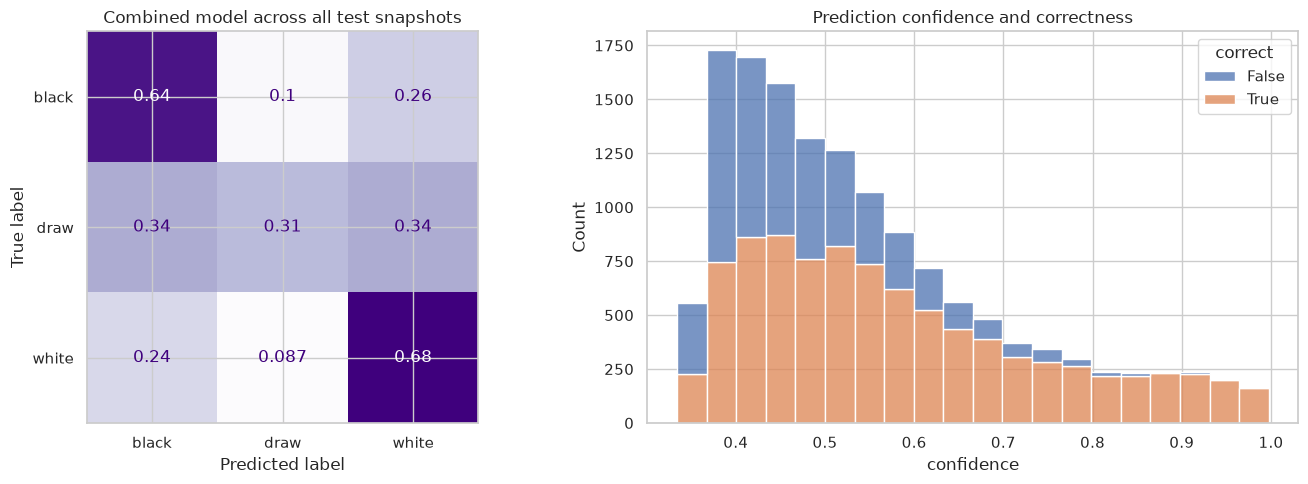

              precision    recall  f1-score   support

       black      0.683     0.636     0.659      6447
        draw      0.140     0.312     0.194       663
       white      0.714     0.677     0.695      7069

    accuracy                          0.641     14179
   macro avg      0.513     0.542     0.516     14179
weighted avg      0.673     0.641     0.655     14179



In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    test_snapshots["target"],
    combined_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Purples",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Combined model across all test snapshots")

confidence = combined_test_proba.max(axis=1)
correct = combined_test_proba.argmax(axis=1) == test_snapshots["target"].to_numpy()
confidence_frame = pd.DataFrame({"confidence": confidence, "correct": correct})
sns.histplot(data=confidence_frame, x="confidence", hue="correct", bins=20, multiple="stack", ax=axes[1])
axes[1].set_title("Prediction confidence and correctness")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "07_combined_confusion_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(
    test_snapshots["target"],
    combined_test_proba.argmax(axis=1),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

## 8. Conclusions, limitations, and responsible interpretation

The executed tables above provide the defensible conclusions:

1. **Pre-match signal:** compare the selected model with the majority dummy. Rating difference and Elo expectation should carry most of the genuine pre-game signal; importance is predictive, not causal.
2. **Feature ablation:** the validation table quantifies whether positional features add value beyond material. Negative or tiny permutation importance means a feature can be removed without loss.
3. **CNN comparison:** the CNN tests whether learned spatial representations outperform domain-designed features under the same game split and fixed-ply modelling protocol. A small dataset and short CPU training budget may favour handcrafted inductive bias.
4. **Progressive update:** the final curve is the main result. Area under the performance-progress curve rewards models that become accurate early rather than only near the end.
5. **Honest terminal semantics:** the endpoint is not forced to 100%. Resignation and timeout outcomes are not logically recoverable from a board position, so the final point remains a pure prediction.

### Limitations

- Games come from one historical Lichess sample; performance may shift across rating pools, time periods, platforms, or over-the-board chess.
- Random stratified splitting estimates performance on similar future samples. A chronological split would better test temporal drift, while a player-group split would test unseen-player generalisation.
- Percentage checkpoints use final length only to choose retrospective test evaluation positions. The deployed models themselves accept current ply and can update after any move without knowing final game length.
- The dataset has no per-move clocks, so the model cannot observe time pressure. This especially limits timeout prediction.
- Macro-F1 treats all classes equally but does not assess probability calibration. Reliability diagrams or expected calibration error would be useful extensions.
- Stacking uses the validation set to fit the meta-model. Nested cross-fitting would reduce selection variance in a larger study.


### Generative AI use declaration

OpenAI Codex was used to assist with structuring the analysis, drafting Python code, debugging, and language editing for the notebook, report, and README. The project authors reviewed and validated all generated content, methodological decisions, code execution, numerical results, references, and interpretations, and retain full responsibility for the submitted work. No generative-AI-produced observations, outcomes, or labels were added to the dataset.